In [1]:
%load_ext autoreload
%autoreload 2

from model import validate_classifier, train_final_classifier
from database import load_tables, postgres_engine
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

users, posts, feed = load_tables(postgres_engine())

0:	learn: 0.6740143	total: 789ms	remaining: 6m 33s
100:	learn: 0.5932275	total: 1m 10s	remaining: 4m 38s
200:	learn: 0.5923136	total: 2m 18s	remaining: 3m 25s
300:	learn: 0.5917851	total: 3m 30s	remaining: 2m 19s
400:	learn: 0.5914005	total: 4m 45s	remaining: 1m 10s
499:	learn: 0.5911056	total: 6m	remaining: 0us
train_roc_auc: 0.7049
test_roc_auc: 0.6803
train_group_auc: 0.6824
test_group_auc: 0.6621


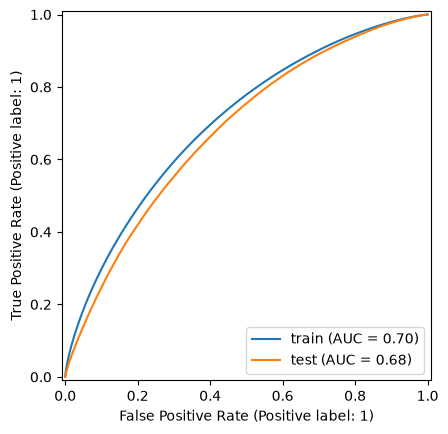

In [2]:
model, metrics, train_df, test_df = validate_classifier(users, posts, feed)
for name, value in metrics.items():
    print(f'{name}: {value:.4f}')

fig, ax = plt.subplots(1, 1)

RocCurveDisplay.from_predictions(train_df['target'], train_df['p'], ax=ax, name='train')
RocCurveDisplay.from_predictions(test_df['target'], test_df['p'], ax=ax, name='test')

In [3]:
# освобождаем память перед финальным обучением
del model, train_df, test_df

In [4]:
train_final_classifier(users, posts, feed)

0:	learn: 0.6733140	total: 823ms	remaining: 6m 50s
100:	learn: 0.5898033	total: 1m 22s	remaining: 5m 27s
200:	learn: 0.5891286	total: 2m 51s	remaining: 4m 15s
300:	learn: 0.5886690	total: 4m 20s	remaining: 2m 52s
400:	learn: 0.5882639	total: 5m 48s	remaining: 1m 25s
499:	learn: 0.5880113	total: 7m 16s	remaining: 0us
